## Step 1 : Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the cleaned blood bank dataset
file_path = Path("dataset/processed/blood_banks_cleaned.csv")
candidates = [base / file_path for base in (Path.cwd(), *Path.cwd().parents)]
file_path = next((path for path in candidates if path.is_file()), None)

if file_path is None:
    # Search within the project in case the dataset is in a different subfolder.
    project_root = Path.cwd().parent if Path.cwd().name.lower() == "notebook" else Path.cwd()
    matches = list(project_root.rglob("blood_banks_cleaned.csv"))

    if matches:
        file_path = matches[0]
    else:
        raise FileNotFoundError(
            f"blood_banks_cleaned.csv was not found under {project_root}. "
            "Add the cleaned dataset to dataset/processed/ or update file_path."
        )

data = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Total Records:", len(data))
print("Total States:", data["state"].nunique())
print("Total Districts:", data["district"].nunique())

Dataset loaded successfully!
Total Records: 2823
Total States: 35
Total Districts: 600


## Step 2 : State-wise blood bank distribution

## 1. India-Wide Blood Bank Distribution

This section analyses how blood banks are distributed across different Indian states and union territories.

In [4]:
state_distribution = (
    data.groupby("state")
    .size()
    .reset_index(name="total_blood_banks")
    .sort_values("total_blood_banks", ascending=False)
)

display(state_distribution.head(10))

,state,total_blood_banks
19,maharashtra,332
29,tamil-nadu,291
32,uttar-pradesh,288
15,karnataka,198
16,kerala,179
30,telangana,149
1,andhra-pradesh,139
18,madhya-pradesh,139
10,gujarat,136
34,west-bengal,117


## Step 3 : Visualize state distribution

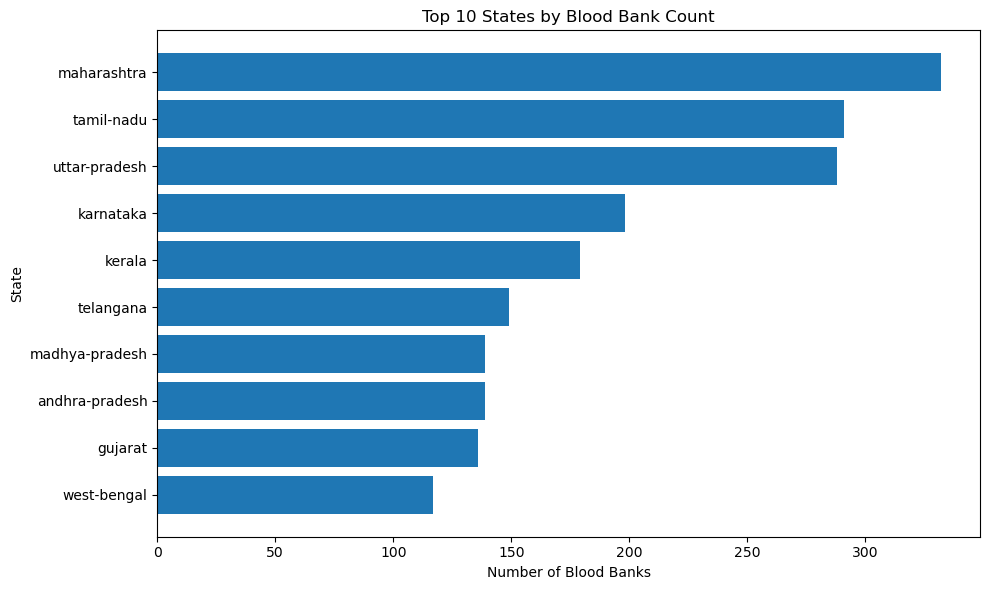

In [5]:
top_states = state_distribution.head(10).sort_values(
    "total_blood_banks"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_states["state"],
    top_states["total_blood_banks"]
)

plt.xlabel("Number of Blood Banks")
plt.ylabel("State")
plt.title("Top 10 States by Blood Bank Count")
plt.tight_layout()
plt.show()

## 2. Karnataka District-Wise Analysis

This section examines the distribution of listed blood banks across Karnataka districts.

## Step 4 : Filter Karnataka data

In [6]:
karnataka_data = data[
    data["state"].str.strip().str.lower() == "karnataka"
].copy()

print("Total Blood Banks in Karnataka:", len(karnataka_data))
print("Total Districts:", karnataka_data["district"].nunique())

display(karnataka_data.head())

Total Blood Banks in Karnataka: 198
Total Districts: 30


,state,district,city,name,address,pin,phone,helpline,website,category,components,apheresis,hours,lat,lon
750,karnataka,Bagalkot,Bagalkot,B. V. V. Sanghas HSK Hospital Blood Bank,"Navanagar, Bagalkot",587102.0,08352 235410,NaN,NaN,Private,True,True,24x7,16.16508,75.67507
751,karnataka,Bagalkot,Bagalkot,Bagalkot Blood Bank,Hanagal Shree Kumareshwar Hospital and Researc...,587101.0,0835 220420,NaN,NaN,Private,False,False,24x7,16.18613,75.70653
752,karnataka,Bagalkot,Bagalkot,District Hospital Blood Bank Bagalkot,Navanagar,587101.0,0835 4236030,NaN,NaN,Government,False,False,24x7,16.16501,75.66081
753,karnataka,Bagalkot,Ilkal,M/s. Vijay Mahant Blood Bank,Sri Basaveshwara Childrens Hospital & Research...,587125.0,08351 270838,NaN,NaN,Private,True,False,24x7,NaN,NaN
754,karnataka,Bagalkot,Jamkhandi,Mounesh Hospital's The Jhamkandi Blood Bank,"Near P.B. High School, Uma Rameshwar Road",587101.0,08353 22357,NaN,NaN,Private,False,False,24x7,NaN,NaN


## Step 5 : District-wise distribution

In [7]:
district_distribution = (
    karnataka_data.groupby("district")
    .size()
    .reset_index(name="total_blood_banks")
    .sort_values("total_blood_banks", ascending=False)
)

display(district_distribution)

,district,total_blood_banks
4,Bengaluru Urban,62
11,Dakshina Kannada,16
22,Mysore,13
13,Dharwad,11
1,Belgaum,7
0,Bagalkot,7
25,Shivamogga,7
17,Kalaburagi,6
12,Davangere,6
6,Bijapur,6


## Step 6 : Identify districts with fewer listed blood banks

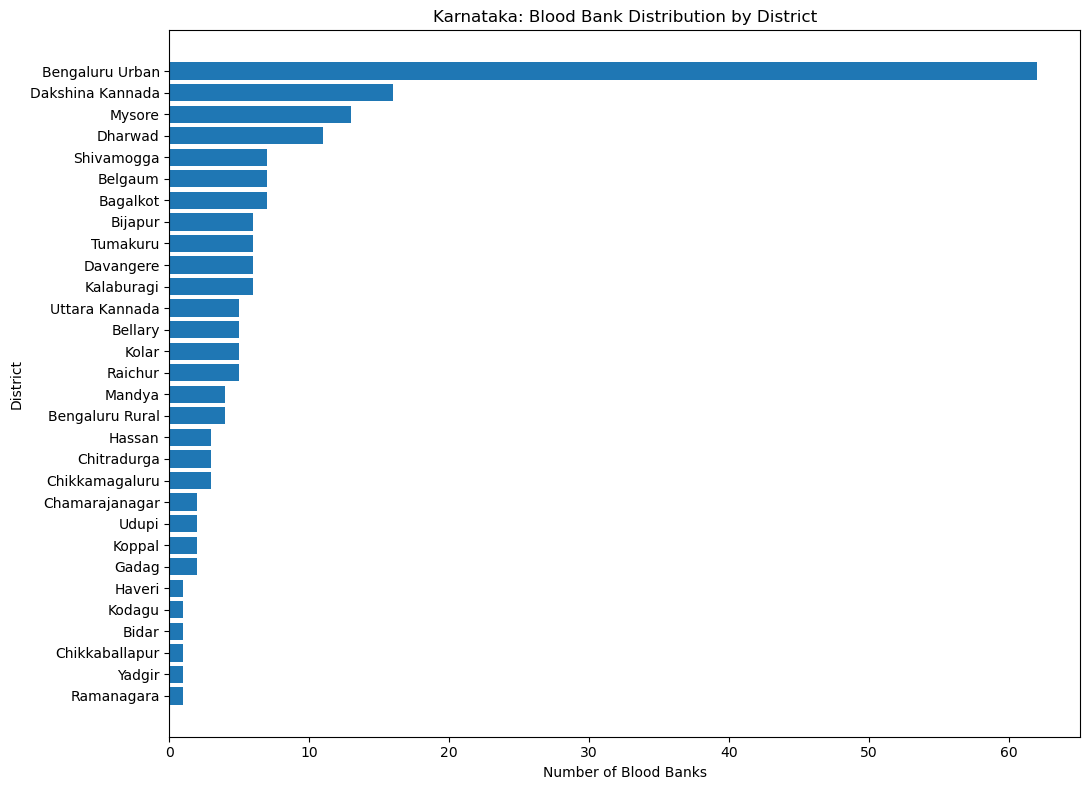

Five districts with the fewest listed blood banks:


,district,total_blood_banks
24,Ramanagara,1
29,Yadgir,1
8,Chikkaballapur,1
5,Bidar,1
18,Kodagu,1


In [8]:
district_distribution_sorted = district_distribution.sort_values(
    "total_blood_banks"
)

plt.figure(figsize=(11, 8))

plt.barh(
    district_distribution_sorted["district"],
    district_distribution_sorted["total_blood_banks"]
)

plt.xlabel("Number of Blood Banks")
plt.ylabel("District")
plt.title("Karnataka: Blood Bank Distribution by District")
plt.tight_layout()
plt.show()

print("Five districts with the fewest listed blood banks:")
display(district_distribution.head(0) if False else district_distribution_sorted.head(5))

## 3. Blood Bank Category Analysis

This section examines the different categories of blood banks in Karnataka.

## Step 7 : Blood bank category analysis

In [9]:
category_distribution = (
    karnataka_data["category"]
    .fillna("Not Specified")
    .value_counts()
    .reset_index()
)

category_distribution.columns = ["category", "total_blood_banks"]

display(category_distribution)

,category,total_blood_banks
0,Private,130
1,Government,41
2,Charity,27


## Step 8 : Category visualization

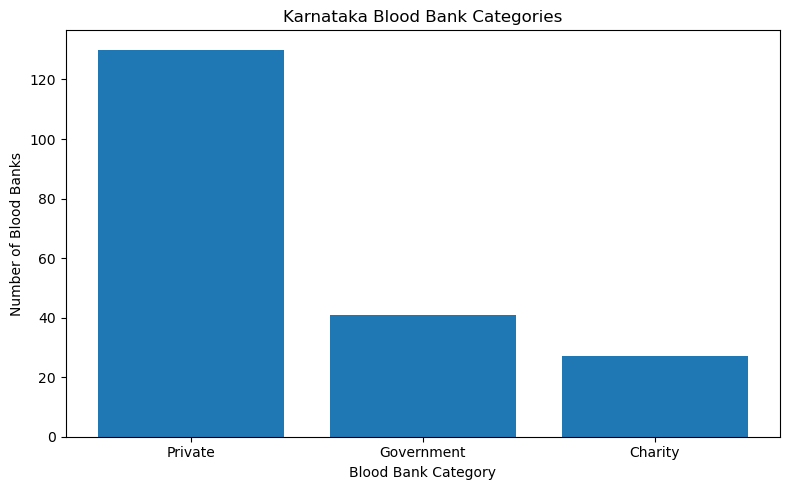

In [10]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_distribution["category"],
    category_distribution["total_blood_banks"]
)

plt.xlabel("Blood Bank Category")
plt.ylabel("Number of Blood Banks")
plt.title("Karnataka Blood Bank Categories")

plt.tight_layout()
plt.show()

## Step 9 : Facility availability analysis

In [11]:
facility_summary = pd.DataFrame({
    "Facility": [
        "Blood Components",
        "Apheresis"
    ],
    "Available Records": [
        karnataka_data["components"].astype(str).str.lower().isin(["true", "1", "yes"]).sum(),
        karnataka_data["apheresis"].astype(str).str.lower().isin(["true", "1", "yes"]).sum()
    ]
})

display(facility_summary)

,Facility,Available Records
0,Blood Components,85
1,Apheresis,24


## 4. Geographical Coverage Analysis

This section examines the geographical locations of blood banks using latitude and longitude.

It helps visualize the distribution of listed blood banks across India and Karnataka.

In [12]:
# Select records with valid geographical coordinates
geo_data = data.dropna(subset=["lat", "lon"]).copy()

geo_data = geo_data[
    geo_data["lat"].between(-90, 90)
    & geo_data["lon"].between(-180, 180)
]

print("Total Blood Banks:", len(data))
print("Blood Banks with Valid Coordinates:", len(geo_data))
print("Records without Valid Coordinates:", len(data) - len(geo_data))

Total Blood Banks: 2823
Blood Banks with Valid Coordinates: 2439
Records without Valid Coordinates: 384


## Step 10 : India geographical distribution map

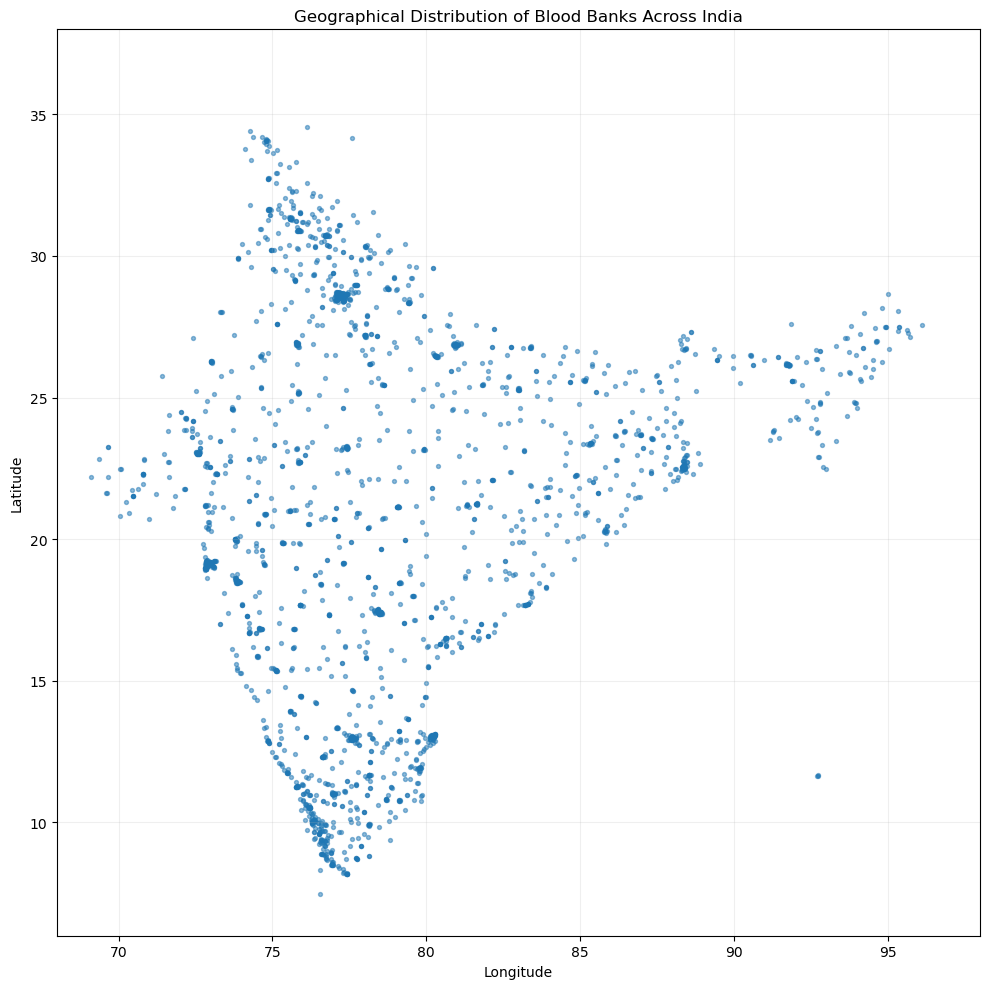

In [13]:
plt.figure(figsize=(10, 10))

plt.scatter(
    geo_data["lon"],
    geo_data["lat"],
    s=8,
    alpha=0.5
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Blood Banks Across India")

plt.xlim(68, 98)
plt.ylim(6, 38)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Step 11 : Karnataka geographical distribution

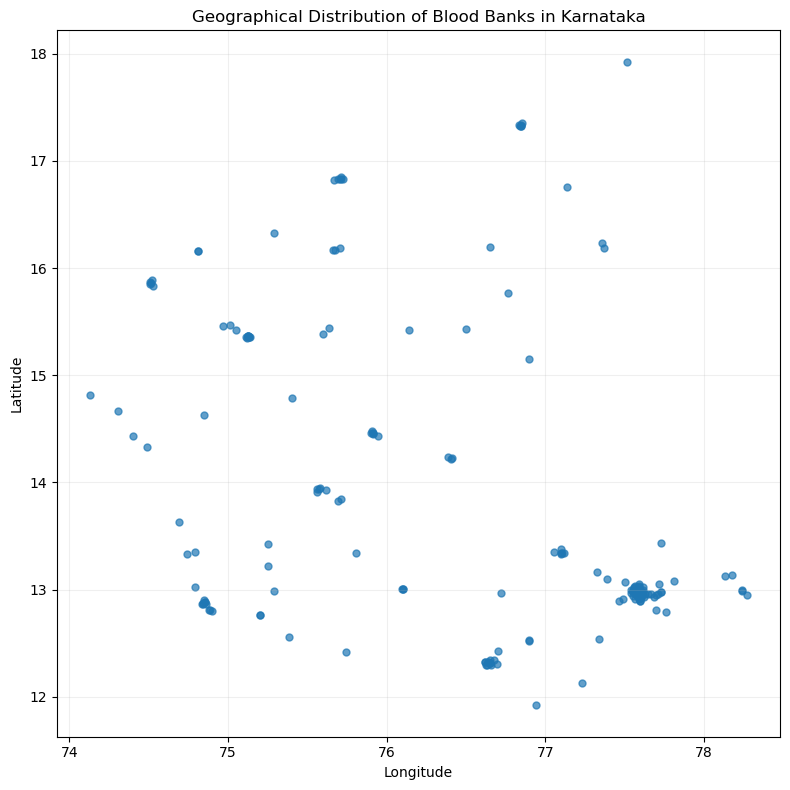

Karnataka Blood Banks with Valid Coordinates: 192


In [14]:
karnataka_geo = geo_data[
    geo_data["state"].str.strip().str.lower() == "karnataka"
].copy()

plt.figure(figsize=(8, 8))

plt.scatter(
    karnataka_geo["lon"],
    karnataka_geo["lat"],
    s=25,
    alpha=0.7
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Blood Banks in Karnataka")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Karnataka Blood Banks with Valid Coordinates:", len(karnataka_geo))

## 5. District-Wise Coverage Classification

Districts are classified according to the number of blood banks listed in the dataset.

This is a comparative directory-count analysis, not a measure of actual healthcare demand or shortage.

In [15]:
# Calculate the average number of listed blood banks per district
average_banks = district_distribution["total_blood_banks"].mean()

def classify_coverage(count):
    if count < average_banks * 0.5:
        return "Low"
    elif count < average_banks:
        return "Moderate"
    else:
        return "High"

district_distribution["coverage_level"] = (
    district_distribution["total_blood_banks"]
    .apply(classify_coverage)
)

print("Average Blood Banks per District:", round(average_banks, 2))

display(
    district_distribution.sort_values(
        "total_blood_banks",
        ascending=True
    )
)

Average Blood Banks per District: 6.6


,district,total_blood_banks,coverage_level
24,Ramanagara,1,Low
29,Yadgir,1,Low
8,Chikkaballapur,1,Low
5,Bidar,1,Low
18,Kodagu,1,Low
16,Haveri,1,Low
14,Gadag,2,Low
20,Koppal,2,Low
27,Udupi,2,Low
7,Chamarajanagar,2,Low


## Step 12 : Coverage classification summary

,Coverage Level,Number of Districts
0,Low,13
1,Moderate,10
2,High,7


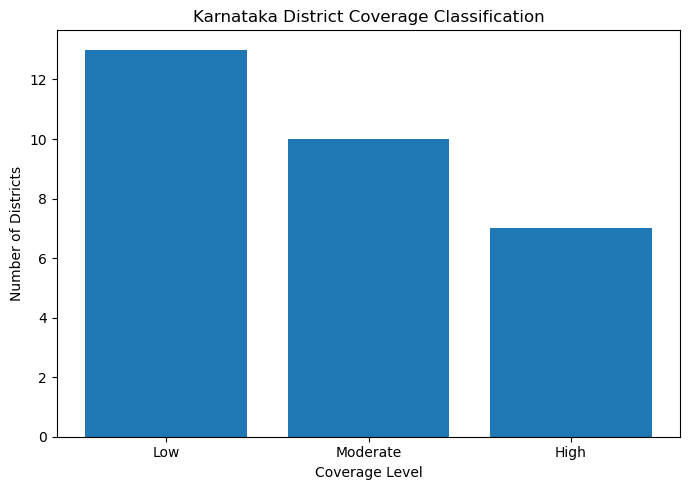

In [16]:
coverage_summary = (
    district_distribution["coverage_level"]
    .value_counts()
    .reindex(["Low", "Moderate", "High"], fill_value=0)
    .reset_index()
)

coverage_summary.columns = [
    "Coverage Level",
    "Number of Districts"
]

display(coverage_summary)

plt.figure(figsize=(7, 5))

plt.bar(
    coverage_summary["Coverage Level"],
    coverage_summary["Number of Districts"]
)

plt.xlabel("Coverage Level")
plt.ylabel("Number of Districts")
plt.title("Karnataka District Coverage Classification")

plt.tight_layout()
plt.show()

## 6. Export Geographical Analysis Results

The state-wise distribution, Karnataka district analysis, category distribution and coverage classification are exported for use in the BloodLink dashboard.

In [17]:
from pathlib import Path

results_folder = Path("results")
results_folder.mkdir(parents=True, exist_ok=True)

# Save state-wise distribution
state_distribution.to_csv(
    results_folder / "state_distribution.csv",
    index=False
)

# Save Karnataka district analysis
district_distribution.to_csv(
    results_folder / "karnataka_district_analysis.csv",
    index=False
)

# Save category analysis
category_distribution.to_csv(
    results_folder / "karnataka_category_analysis.csv",
    index=False
)

# Save facility analysis
facility_summary.to_csv(
    results_folder / "karnataka_facility_analysis.csv",
    index=False
)

# Save coverage classification
coverage_summary.to_csv(
    results_folder / "karnataka_coverage_summary.csv",
    index=False
)

# Save geographical records
geo_data.to_csv(
    results_folder / "blood_bank_geographical_data.csv",
    index=False
)

print("Geographical analysis results saved successfully!")

print("\nFiles created:")
for file in sorted(results_folder.glob("*.csv")):
    print("-", file.name)

Geographical analysis results saved successfully!

Files created:
- blood_bank_geographical_data.csv
- karnataka_category_analysis.csv
- karnataka_coverage_summary.csv
- karnataka_district_analysis.csv
- karnataka_facility_analysis.csv
- state_distribution.csv
